# Week 4 · Part B — Smoothing, windows and panel shape, computed
**Data Visualization (CDB601220)**

Every number below is **computed**, not eyeballed. The input is the **cleaned daily session series from Part D** (parsed, de-duplicated, sentinels removed, resampled to daily with `sum(min_count=24)`, gap days left as `NaN`). The cleaning lives in `w4_clean.py` so Part B and Part D use exactly the same series.

> **How to run:** keep this notebook in `week4/assignments/` and run *Restart & Run All*. It needs `w4_clean.py`, `tslib.py`, `vizlib.py` and `data/`.

In [4]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")

HERE = Path.cwd()                      # run the notebook from week4/assignments
DATA = HERE / "data"
OUT  = HERE / "outputs"; OUT.mkdir(exist_ok=True)
sys.path.insert(0, str(HERE))

import tslib as T                      # Week 4 toolkit (imports Week 3's vizlib)
from tslib import PALETTE, style_defaults, save_fig
style_defaults()
BLUE, ORANGE, GREEN = PALETTE["series"]
PINK, GREY, INK = PALETTE["series_4th"], PALETTE["muted"], PALETTE["ink"]
SOFT = PALETTE["ink_soft"]
SRC = "Source: CDB601220 Week 4 synthetic course data (Superior University Lahore)."

import w4_clean as W
from scipy import stats
from statsmodels.tsa.seasonal import seasonal_decompose

PB = OUT / "partB"; PB.mkdir(exist_ok=True)
res = W.run_all(DATA / "sessions_hourly.csv")
daily = res["daily"]
s = daily.sessions                       # sessions per day (sum of hourly); 13 gap days are NaN
print(f"daily series: {s.index.min().date()} -> {s.index.max().date()}, {len(s)} calendar days, {int(s.isna().sum())} NaN gap days")
print("audit_index:", {k: v for k, v in T.audit_index(s.dropna(), "D").items() if k in ("dtype_ok", "monotonic", "n_duplicated", "n_missing", "partial_tail", "tail_period", "tail_count")})
results = {}

daily series: 2024-04-01 -> 2025-09-11, 529 calendar days, 13 NaN gap days
audit_index: {'dtype_ok': True, 'monotonic': True, 'n_duplicated': 0, 'n_missing': 13, 'partial_tail': True, 'tail_period': '2025-09', 'tail_count': 11}


---
## B.1 · The window is a hypothesis  *(4 marks)*
`tslib.window_report()` for windows 7, 28 and 91 (centred).

In [5]:
wr = T.window_report(s, (7, 28, 91), center=True)
cycle = {7: "weekly rhythm (exactly one cycle)",
         28: "weekly rhythm (4 cycles) + month-scale wobble",
         91: "weekly + monthly + part of the quarterly/seasonal swing"}
wr["cycle_removed"] = wr.window.map(cycle)
display(wr)
results["B1"] = wr.drop(columns="cycle_removed").to_dict("records")

,window,raw_sd,smoothed_sd,variation_removed_pct,periods_lost_each_end,cycle_removed
0,7,6783.3436,4635.3973,31.7,3,weekly rhythm (exactly one cycle)
1,28,6783.3436,4427.7210,34.7,14,weekly rhythm (4 cycles) + month-scale wobble
2,91,6783.3436,4144.1547,38.9,45,weekly + monthly + part of the quarterly/seaso...


| Window | Cycle it removes | Share of raw variation removed | Periods lost at each end |
|---|---|---|---|
| **7** | the weekly rhythm — one full period | **31.7%** | **3** |
| **28** | the weekly rhythm four times over, plus month-scale wobble | **34.7%** | **14** |
| **91** | weekly, monthly *and* a large part of the real seasonal swing | **38.9%** | **45** |

**Which window I use in Part D: 7 days.** The reason is the cycle being cancelled, not smoothness. The weekend/weekday rhythm repeats every 7 days, so a 7-day window averages exactly one cycle and cancels it: Saturday and Sunday (+4,978 and +5,284 against the mean) are balanced by the weekdays inside the same window. A window that is not a multiple of 7 leaves a ripple at the weekly frequency; one much longer than 7 starts removing the **seasonal trajectory leadership needs to see**. Going from 7 to 28 days removes only 3 more points of variation (31.7% → 34.7%) but costs **14 days** at each end instead of 3; going to 91 days costs **45 days** at each end — roughly 17% of the 529-day series — and starts flattening the genuine Oct–Nov ramp. The extra "smoothness" is mostly the real signal.

---
## B.2 · Three smoothers against one spike  *(3 marks)*
29 November 2024 is Black Friday. 14-day centred **mean**, **median** and **EWMA** at that date.

,value,vs fortnight median
"raw (113,710 expected)",113710.0,4.59x
14-day centred MEAN,33403.0,1.35x
14-day centred MEDIAN,24766.0,1.0x
"EWMA (span 14, trailing)",37978.0,1.53x
fortnight median (+/-7 days),24760.0,1.0x


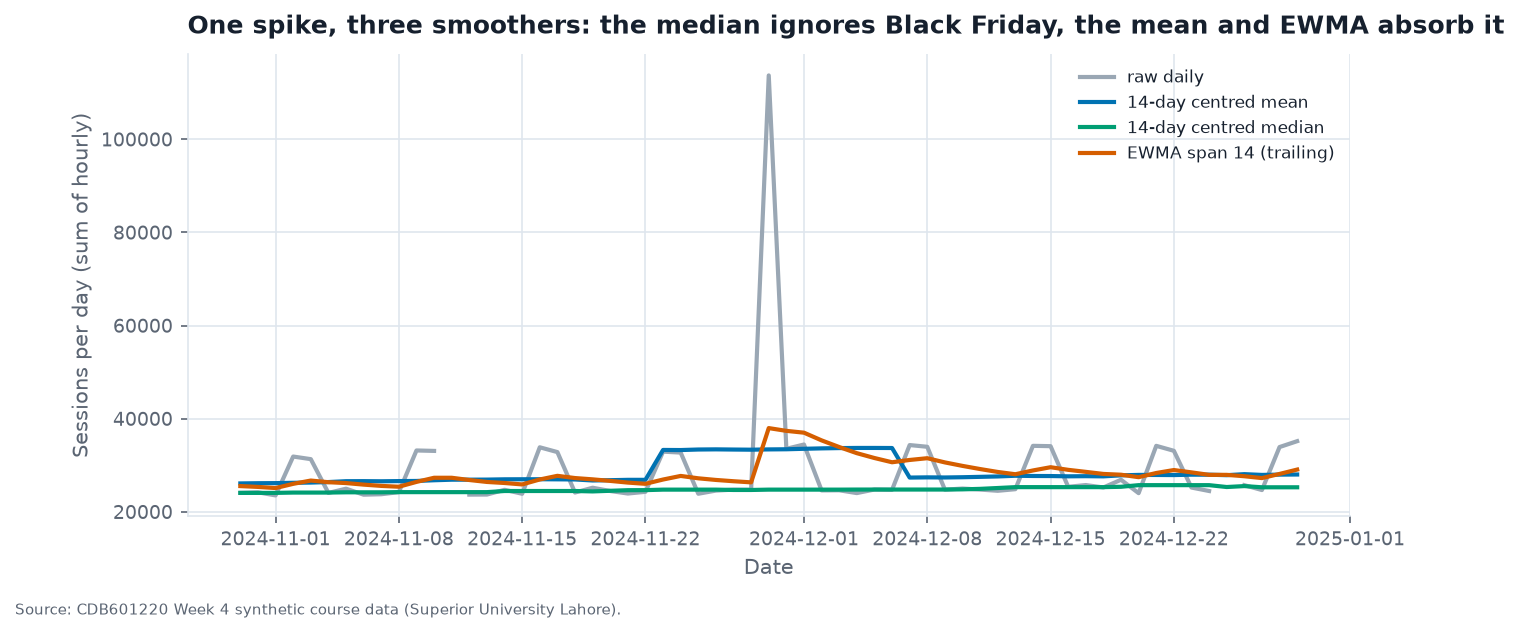

In [6]:
bf = pd.Timestamp("2024-11-29")
raw_bf = float(s[bf])
mean14 = float(s.rolling(14, center=True, min_periods=7).mean()[bf])
med14  = float(s.rolling(14, center=True, min_periods=7).median()[bf])
ewma14 = float(s.ewm(span=14, adjust=False, ignore_na=True).mean()[bf])   # EWMA is trailing by construction
fortnight = float(s[bf - pd.Timedelta(days=7): bf + pd.Timedelta(days=7)].median())
tab = pd.DataFrame({"value": [raw_bf, mean14, med14, ewma14, fortnight]},
                   index=["raw (113,710 expected)", "14-day centred MEAN", "14-day centred MEDIAN",
                          "EWMA (span 14, trailing)", "fortnight median (+/-7 days)"])
tab["vs fortnight median"] = (tab.value / fortnight).round(2).astype(str) + "x"
display(tab.round(0))
assert raw_bf == 113710
results["B2"] = {"raw": raw_bf, "mean14": mean14, "median14": med14, "ewma14": ewma14, "fortnight_median": fortnight}

fig, ax = plt.subplots(figsize=(10, 4))
win = s[bf - pd.Timedelta(days=30): bf + pd.Timedelta(days=30)]
ax.plot(win.index, win, color=GREY, label="raw daily")
ax.plot(win.index, s.rolling(14, center=True, min_periods=7).mean()[win.index], color=BLUE, label="14-day centred mean")
ax.plot(win.index, s.rolling(14, center=True, min_periods=7).median()[win.index], color=GREEN, label="14-day centred median")
ax.plot(win.index, s.ewm(span=14, adjust=False, ignore_na=True).mean()[win.index], color=ORANGE, label="EWMA span 14 (trailing)")
ax.set_title("One spike, three smoothers: the median ignores Black Friday, the mean and EWMA absorb it")
ax.set_xlabel("Date"); ax.set_ylabel("Sessions per day (sum of hourly)"); ax.legend(fontsize=8)
save_fig(fig, PB / "B2_smoothers.png", note=SRC); plt.show()

At 29 Nov 2024 the **raw** value is **113,710** against a fortnight median of about **24,766**. The 14-day centred **mean** is **33,403**, the centred **median** is **24,766**, and the **EWMA** (span 14, trailing) is **37,978**.

- **Monitoring dashboard → EWMA.** It reacts the moment the spike arrives (38.0k vs a 24.8k baseline — a 53% jump), can be computed on live data with no future points, and is cheap to update. Its job is to make an anomaly *noticeable*.
- **Quarterly report → centred median.** It stays at the typical level (24.8k, identical to the fortnight median) and is not dragged up by a one-day event, so the line shows the underlying trajectory. The spike is still on the chart as raw grey; the median simply refuses to let one day rewrite the trend.

---
## B.3 · Decompose it  *(3 marks)*
`seasonal_decompose(..., model="additive", period=7)`. `seasonal_decompose` cannot take `NaN`, so the **13 gap days are linearly interpolated for this one computation only** — they are not plotted and not used anywhere else.

interpolated for decomposition only: 13 gap days
weekly seasonal component (sessions vs trend): {'Mon': -2230.0, 'Tue': -2330.0, 'Wed': -2349.0, 'Thu': -2332.0, 'Fri': -1021.0, 'Sat': 4978.0, 'Sun': 5284.0}
peak-to-trough amplitude of the weekly component: 7,633 sessions/day
largest residual: 2024-11-29  (+74,676 sessions)   next four: [('2024-12-02', 13133), ('2024-11-28', 12860), ('2024-11-26', 12728), ('2024-11-27', 12584)]
period=365 -> x must have 2 complete cycles requires 730 observations. x only has 529 observation(s)


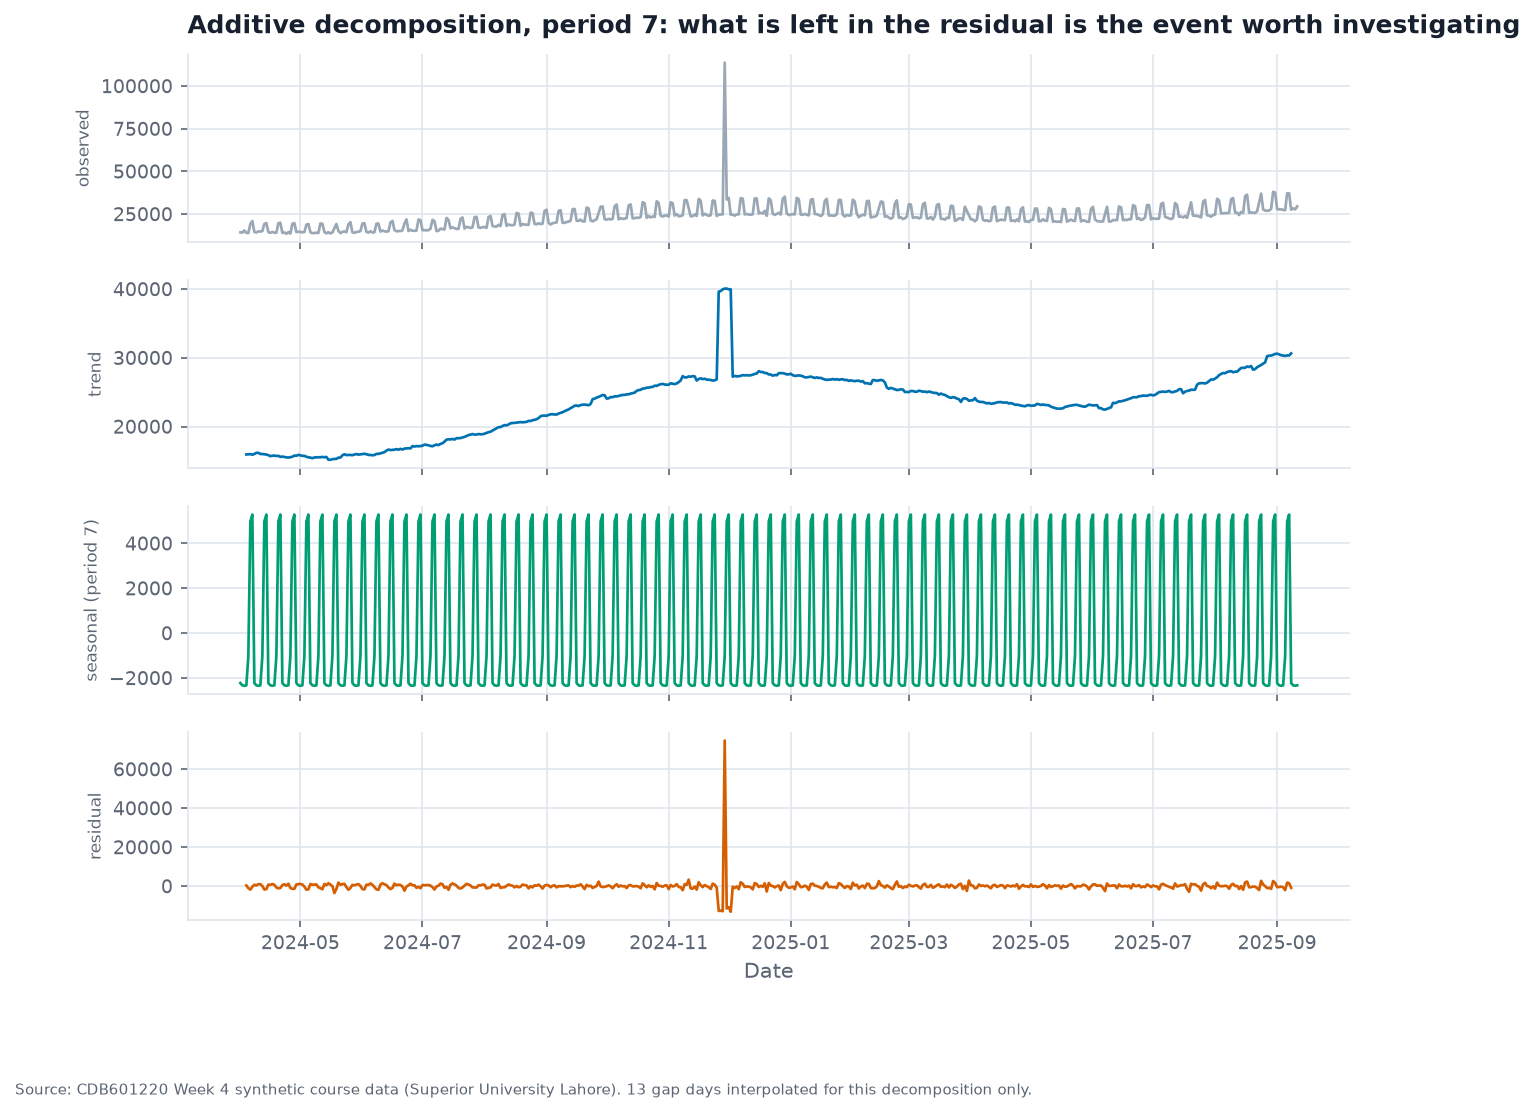

In [7]:
s_int = s.interpolate(limit_direction="both")
print(f"interpolated for decomposition only: {int(s.isna().sum())} gap days")
dec7 = seasonal_decompose(s_int, model="additive", period=7)
week = dec7.seasonal.iloc[:7]
amp = float(week.max() - week.min())
dow = dec7.seasonal.groupby(dec7.seasonal.index.dayofweek).first().round(0)
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print("weekly seasonal component (sessions vs trend):", dow.to_dict())
print(f"peak-to-trough amplitude of the weekly component: {amp:,.0f} sessions/day")
resid = dec7.resid.dropna()
big = resid.abs().idxmax()
print(f"largest residual: {big.date()}  ({resid[big]:+,.0f} sessions)   next four:",
      [(d.date().isoformat(), int(v)) for d, v in resid.abs().nlargest(5).iloc[1:].items()])
results["B3"] = {"weekly_amplitude": amp, "largest_resid_date": str(big.date()), "largest_resid": float(resid[big])}
try:
    seasonal_decompose(s_int, model="additive", period=365)
except ValueError as e:
    print("period=365 ->", e)
    results["B3"]["period365_error"] = str(e)

fig, axes = plt.subplots(4, 1, figsize=(10, 7.5), sharex=True)
for ax, (name, ser, col) in zip(axes, [("observed", dec7.observed, GREY), ("trend", dec7.trend, BLUE),
                                       ("seasonal (period 7)", dec7.seasonal, GREEN), ("residual", dec7.resid, ORANGE)]):
    ax.plot(ser.index, ser, color=col, linewidth=1.3); ax.set_ylabel(name, fontsize=8)
axes[0].set_title("Additive decomposition, period 7: what is left in the residual is the event worth investigating")
axes[-1].set_xlabel("Date")
save_fig(fig, PB / "B3_decomposition.png", note=SRC + " 13 gap days interpolated for this decomposition only."); plt.show()

- **Peak-to-trough amplitude of the weekly component: 7,633 sessions/day.** Sunday sits about **+5,284** above trend, Wednesday about **−2,349**.
- **Largest residual: 29 November 2024** (about **+74,676** sessions) — Black Friday. Once trend and the weekly rhythm are removed, that one day is by far the largest unexplained quantity (the next largest residual is under 14,000).
- **`period=365`:** `seasonal_decompose` **refuses to run** — it needs two complete cycles (730 observations) and the series has 529. That is itself the answer to the hypothesis: this file is too short to *estimate* an annual season at all. With two or more years, the slow annual swing now sitting in `trend` (the climb from April to the November peak and the decline after) would move **into `seasonal`**, and a date-locked event such as Black Friday would then be partly absorbed into `seasonal` instead of standing out in `resid`. I state that as expectation, not as a computed result.

---
## B.4 · Trailing or centred  *(2 marks)*
`tslib.lag_at_turn()` with a 31-day window on the series.

In [8]:
lag_max = T.lag_at_turn(s, 31, how="max")
lag_min = T.lag_at_turn(s, 31, how="min")
for name, lg in (("seasonal peak (max)", lag_max), ("seasonal low (min)", lag_min)):
    print(f"{name:<20} trailing {lg['trailing_turn'].date()} | centred {lg['centred_turn'].date()} | "
          f"lag {lg['lag_periods']} days | half-window {lg['half_window']}")
results["B4"] = {"peak": {"trailing": str(lag_max["trailing_turn"].date()), "centred": str(lag_max["centred_turn"].date()), "lag": lag_max["lag_periods"]},
                 "low": {"trailing": str(lag_min["trailing_turn"].date()), "centred": str(lag_min["centred_turn"].date()), "lag": lag_min["lag_periods"]},
                 "half_window": lag_max["half_window"]}

seasonal peak (max)  trailing 2024-12-23 | centred 2024-12-08 | lag 15 days | half-window 15
seasonal low (min)   trailing 2024-05-16 | centred 2024-05-01 | lag 15 days | half-window 15


The lag is **15 days against a half-window of 15** — for the seasonal peak (trailing mean peaks 23 Dec 2024, centred mean peaks 8 Dec 2024) and equally for the seasonal low (16 May vs 1 May 2024). It is arithmetic: a trailing window cannot know a turn has happened until half the window is filled with post-turn days.

**A live dashboard that refreshes every morning must show the trailing mean**, because tomorrow's data does not exist yet and a centred window needs 15 future days. The caption must say so: *"31-day trailing mean; a turning point appears about 15 days after it happens."* A centred mean is for retrospective reports only.

---
## B.5 · The window is a claim  *(3 marks)*
12 start months × 5 window lengths (7, 14, 28, 56, 91 days) = 60 combinations on the same unchanged series. Start months are the first 12 month-starts in the file (Apr 2024 – Mar 2025); each segment is `[start, start + window − 1 days]`, `NaN` gap days dropped, and a straight line fitted by least squares against day number.

60 combinations -> RISING: 34   FALLING: 26
  of which significant at p<0.05: rising 10, falling 8; not significant: 42
the whole series, no window chosen: slope = +21.6 sessions/day per day (p=2.1e-30)


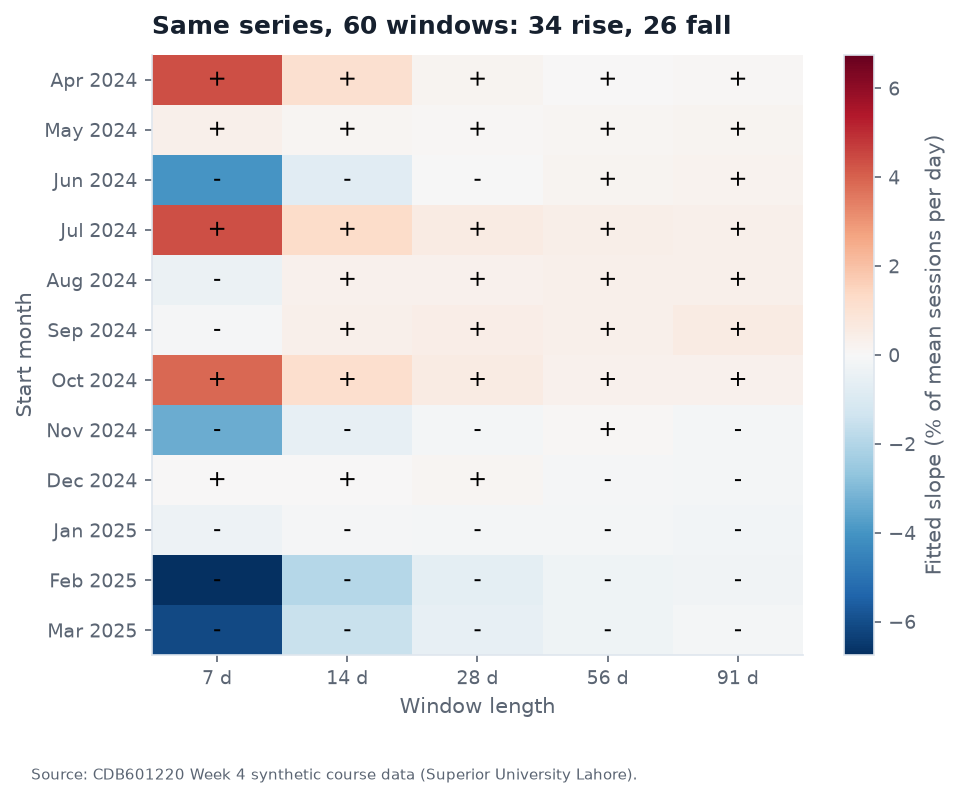

In [9]:
starts = pd.date_range(s.index.min().normalize().replace(day=1), periods=12, freq="MS")
windows = (7, 14, 28, 56, 91)
rows = []
for st in starts:
    for wl in windows:
        seg = s[st: st + pd.Timedelta(days=wl - 1)].dropna()
        x = (seg.index - seg.index[0]).days.to_numpy()
        r = stats.linregress(x, seg.to_numpy(float))
        rows.append({"start": st, "window": wl, "n": len(seg), "slope": r.slope, "p": r.pvalue})
grid = pd.DataFrame(rows)
n_rise, n_fall = int((grid.slope > 0).sum()), int((grid.slope < 0).sum())
n_rise_sig = int(((grid.slope > 0) & (grid.p < 0.05)).sum()); n_fall_sig = int(((grid.slope < 0) & (grid.p < 0.05)).sum())
print(f"{len(grid)} combinations -> RISING: {n_rise}   FALLING: {n_fall}")
print(f"  of which significant at p<0.05: rising {n_rise_sig}, falling {n_fall_sig}; not significant: {len(grid)-n_rise_sig-n_fall_sig}")
full = stats.linregress(np.arange(s.notna().sum()), s.dropna().to_numpy(float))
print(f"the whole series, no window chosen: slope = {full.slope:+.1f} sessions/day per day (p={full.pvalue:.1e})")
results["B5"] = {"rising": n_rise, "falling": n_fall, "rising_sig": n_rise_sig, "falling_sig": n_fall_sig,
                 "full_series_slope": float(full.slope)}

piv = grid.pivot(index="start", columns="window", values="slope")
pct = piv.div(s.mean()) * 100
fig, ax = plt.subplots(figsize=(7, 5.2))
lim = np.nanmax(np.abs(pct.to_numpy()))
im = ax.imshow(pct.to_numpy(), cmap=PALETTE["diverging"], vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(5)); ax.set_xticklabels([f"{w} d" for w in windows])
ax.set_yticks(range(12)); ax.set_yticklabels([d.strftime("%b %Y") for d in piv.index])
for i in range(12):
    for j in range(5):
        ax.text(j, i, "+" if pct.iat[i, j] > 0 else "-", ha="center", va="center", fontsize=11, color="black")
ax.grid(False); ax.set_xlabel("Window length"); ax.set_ylabel("Start month")
ax.set_title(f"Same series, 60 windows: {n_rise} rise, {n_fall} fall")
fig.colorbar(im, ax=ax, label="Fitted slope (% of mean sessions per day)")
save_fig(fig, PB / "B5_window_choice.png", note=SRC); plt.show()

**Counts:** of the 60 combinations, **34 produce a rising trend and 26 a falling one** (10 rising and 8 falling are significant at p < 0.05; 42 are not). The *same unchanged series* can be made to say "growing" or "shrinking" by choosing where to start and how long to look. The whole series — no window chosen — rises by about **+21.6 sessions/day per day**.

**Why the Lie Factor cannot be computed for a cherry-picked window.** Tufte's Lie Factor is `(effect shown in the graphic) / (effect in the data)`. It assumes the data *contain one definite effect* to compare against. A hand-picked window has no such denominator: the "effect in the data" depends entirely on the window, and the 60 windows above hold effects of **both signs**. The ratio is undefined — you can only compute a lie factor against a ground truth, and here the choice of window is what creates the truth.

**The honest substitute:** a **window-sensitivity statement** — fix the start and the window *before* looking, say so on the chart and in the write-up, and report how many alternative combinations agree (here 34/60 rising vs 26/60 falling) next to the full-series slope. That turns "the window is a claim" into a claim the reader can check.

In [10]:
# persist for Part E
(OUT / "partB_results.json").write_text(json.dumps(results, indent=2, default=str))
print("saved outputs/partB_results.json")

saved outputs/partB_results.json
